In [4]:
import numpy as np
import pennylane as qml
from pennylane import numpy as pnp
from scipy import stats
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split

rng_seed = 7
np.random.seed(rng_seed)

num_qubits = 4
num_shots = 2000
base_noise = 0.03
scale_factors = [1.0, 1.5, 2.0, 2.5, 3.0]
repeats_per_scale = 10
confidence_level = 0.95

In [3]:
!pip install pennylane

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.3/57.3 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 47.9 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 937.5/937.5 kB 38.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.5/25.5 MB 52.6 MB/s eta 0:00:00:00:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 68.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 167.2/167.2 kB 9.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.8/8.8 MB 81.9 MB/s eta 0:00:00:00:0100:01


In [5]:
iris = load_iris()
binary_mask = iris.target < 2
encoded_features = MinMaxScaler(feature_range=(0.0, np.pi)).fit_transform(iris.data[binary_mask])
bipolar_labels = np.where(iris.target[binary_mask] == 0, 1.0, -1.0)
X_train, X_test, y_train, y_test = train_test_split(
    encoded_features, bipolar_labels, test_size=0.3, random_state=rng_seed, stratify=bipolar_labels)
print("training samples", len(X_train), "test samples", len(X_test))

training samples 70 test samples 30


In [6]:
dev_exact = qml.device("default.mixed", wires=num_qubits)
dev_noisy = qml.device("default.mixed", wires=num_qubits)

def feature_map(features):
    for wire in range(num_qubits):
        qml.RY(features[wire], wires=wire)

def conv_block(block_weights, wire_a, wire_b):
    qml.RY(block_weights[0], wires=wire_a)
    qml.RY(block_weights[1], wires=wire_b)
    qml.CNOT(wires=[wire_a, wire_b])
    qml.RY(block_weights[2], wires=wire_a)
    qml.RY(block_weights[3], wires=wire_b)

def pool_block(pool_weight, control_wire, target_wire):
    qml.CRY(pool_weight, wires=[control_wire, target_wire])

def apply_depolarizing(wires, noise_prob):
    if noise_prob > 0.0:
        for wire in wires:
            qml.DepolarizingChannel(noise_prob, wires=wire)

def qcnn_circuit(features, weights, noise_prob):
    feature_map(features)
    conv_block(weights[0:4], 0, 1)
    conv_block(weights[4:8], 2, 3)
    apply_depolarizing([0, 1, 2, 3], noise_prob)
    pool_block(weights[8], 1, 0)
    pool_block(weights[9], 3, 2)
    apply_depolarizing([0, 2], noise_prob)
    conv_block(weights[10:14], 0, 2)
    apply_depolarizing([0, 2], noise_prob)
    pool_block(weights[14], 2, 0)
    apply_depolarizing([0], noise_prob)
    return qml.expval(qml.PauliZ(0))

model_exact = qml.QNode(qcnn_circuit, dev_exact)
model_noisy = qml.set_shots(qml.QNode(qcnn_circuit, dev_noisy), shots=num_shots)

In [7]:
def predicted_expectations(weights, batch):
    return pnp.stack([model_exact(sample, weights, 0.0) for sample in batch])

def square_loss(weights, batch, targets):
    predictions = predicted_expectations(weights, batch)
    return pnp.mean((predictions - targets) ** 2)

def accuracy_from_expectations(values, targets):
    predicted = np.where(np.asarray(values) >= 0.0, 1.0, -1.0)
    return float(np.mean(predicted == np.asarray(targets)))

weights = pnp.array(np.random.uniform(0.0, np.pi, 15), requires_grad=True)
optimizer = qml.AdamOptimizer(stepsize=0.1)
num_steps = 40

for step in range(num_steps):
    weights, loss_value = optimizer.step_and_cost(
        lambda current: square_loss(current, X_train, y_train), weights)
    if (step + 1) % 10 == 0:
        running = [float(v) for v in predicted_expectations(weights, X_train)]
        print("step", step + 1, "loss", round(float(loss_value), 4),
              "train accuracy", round(accuracy_from_expectations(running, y_train), 3))

weights = pnp.array(np.asarray(weights), requires_grad=False)
train_accuracy = accuracy_from_expectations([float(model_exact(x, weights, 0.0)) for x in X_train], y_train)
test_accuracy = accuracy_from_expectations([float(model_exact(x, weights, 0.0)) for x in X_test], y_test)
print("noiseless train accuracy", round(train_accuracy, 3), "noiseless test accuracy", round(test_accuracy, 3))

step 10 loss 0.0927 train accuracy 1.0
step 20 loss 0.0387 train accuracy 1.0
step 30 loss 0.0221 train accuracy 1.0
step 40 loss 0.0179 train accuracy 1.0
noiseless train accuracy 1.0 noiseless test accuracy 1.0


In [8]:
def collect_noise_curve(features, noise_scales, base, repeats):
    scale_column, value_column = [], []
    for scale in noise_scales:
        noise_prob = scale * base
        for _ in range(repeats):
            scale_column.append(scale)
            value_column.append(float(model_noisy(features, weights, noise_prob)))
    return np.array(scale_column), np.array(value_column)

def polynomial_extrapolation(scales, values, degree, query_points, confidence=confidence_level):
    observed_scales = np.asarray(scales, dtype=float)
    observed_values = np.asarray(values, dtype=float)
    design = np.vander(observed_scales, degree + 1, increasing=True)
    coefficients, _, _, _ = np.linalg.lstsq(design, observed_values, rcond=None)
    residuals = observed_values - design @ coefficients
    degrees_of_freedom = len(observed_values) - (degree + 1)
    residual_variance = float(residuals @ residuals) / degrees_of_freedom
    gram_inverse = np.linalg.inv(design.T @ design)
    query_design = np.vander(np.asarray(query_points, dtype=float), degree + 1, increasing=True)
    predictions = query_design @ coefficients
    leverage = np.einsum("ij,jk,ik->i", query_design, gram_inverse, query_design)
    standard_errors = np.sqrt(residual_variance * leverage)
    t_critical = float(stats.t.ppf(0.5 + confidence / 2.0, degrees_of_freedom))
    lower = predictions - t_critical * standard_errors
    upper = predictions + t_critical * standard_errors
    return predictions, lower, upper

noiseless target -0.9692
unmitigated at base noise -0.771
linear zero-noise estimate -0.9104 interval (np.float64(-0.9272), np.float64(-0.8936)) contains target False
quadratic zero-noise estimate -0.9822 interval (np.float64(-1.0272), np.float64(-0.9371)) contains target True


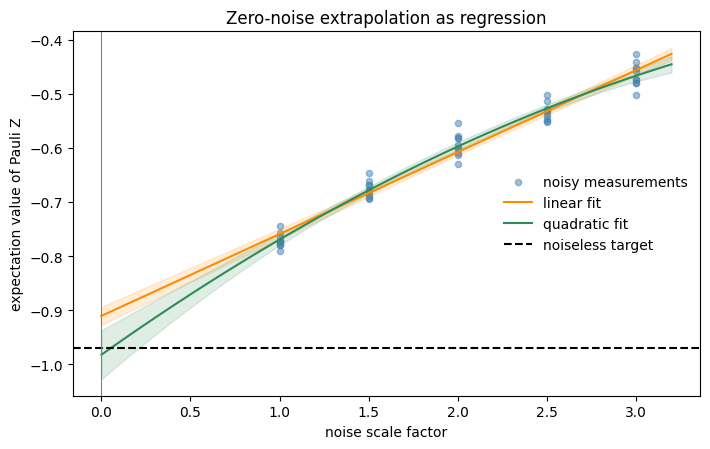

In [9]:
focus_sample = X_test[0]
focus_ideal = float(model_exact(focus_sample, weights, 0.0))
focus_scales, focus_values = collect_noise_curve(focus_sample, scale_factors, base_noise, repeats_per_scale)

(linear_zero,), (linear_low,), (linear_high,) = polynomial_extrapolation(focus_scales, focus_values, 1, [0.0])
(quad_zero,), (quad_low,), (quad_high,) = polynomial_extrapolation(focus_scales, focus_values, 2, [0.0])
focus_unmitigated = float(np.mean(focus_values[focus_scales == 1.0]))

print("noiseless target", round(focus_ideal, 4))
print("unmitigated at base noise", round(focus_unmitigated, 4))
print("linear zero-noise estimate", round(linear_zero, 4),
      "interval", (round(linear_low, 4), round(linear_high, 4)),
      "contains target", bool(linear_low <= focus_ideal <= linear_high))
print("quadratic zero-noise estimate", round(quad_zero, 4),
      "interval", (round(quad_low, 4), round(quad_high, 4)),
      "contains target", bool(quad_low <= focus_ideal <= quad_high))

grid = np.linspace(0.0, max(scale_factors) + 0.2, 120)
linear_curve, linear_band_low, linear_band_high = polynomial_extrapolation(focus_scales, focus_values, 1, grid)
quad_curve, quad_band_low, quad_band_high = polynomial_extrapolation(focus_scales, focus_values, 2, grid)

figure, axis = plt.subplots(figsize=(7.2, 4.6))
axis.scatter(focus_scales, focus_values, s=20, alpha=0.5, color="steelblue", label="noisy measurements")
axis.plot(grid, linear_curve, color="darkorange", label="linear fit")
axis.fill_between(grid, linear_band_low, linear_band_high, color="darkorange", alpha=0.15)
axis.plot(grid, quad_curve, color="seagreen", label="quadratic fit")
axis.fill_between(grid, quad_band_low, quad_band_high, color="seagreen", alpha=0.15)
axis.axhline(focus_ideal, linestyle="--", color="black", label="noiseless target")
axis.axvline(0.0, color="gray", linewidth=0.8)
axis.set_xlabel("noise scale factor")
axis.set_ylabel("expectation value of Pauli Z")
axis.set_title("Zero-noise extrapolation as regression")
axis.legend(frameon=False)
figure.tight_layout()
plt.show()

In [10]:
ideal_values, unmitigated_values, linear_values, quadratic_values = [], [], [], []
linear_coverage, quadratic_coverage = [], []
unmitigated_error, linear_error, quadratic_error = [], [], []

for sample in X_test:
    ideal = float(model_exact(sample, weights, 0.0))
    scales, values = collect_noise_curve(sample, scale_factors, base_noise, repeats_per_scale)
    base_value = float(np.mean(values[scales == 1.0]))
    (lin_point,), (lin_lo,), (lin_hi,) = polynomial_extrapolation(scales, values, 1, [0.0])
    (quad_point,), (quad_lo,), (quad_hi,) = polynomial_extrapolation(scales, values, 2, [0.0])
    ideal_values.append(ideal)
    unmitigated_values.append(base_value)
    linear_values.append(lin_point)
    quadratic_values.append(quad_point)
    linear_coverage.append(lin_lo <= ideal <= lin_hi)
    quadratic_coverage.append(quad_lo <= ideal <= quad_hi)
    unmitigated_error.append((base_value - ideal) ** 2)
    linear_error.append((lin_point - ideal) ** 2)
    quadratic_error.append((quad_point - ideal) ** 2)

print("noiseless accuracy", round(accuracy_from_expectations(ideal_values, y_test), 3))
print("unmitigated accuracy", round(accuracy_from_expectations(unmitigated_values, y_test), 3))
print("linear mitigated accuracy", round(accuracy_from_expectations(linear_values, y_test), 3))
print("quadratic mitigated accuracy", round(accuracy_from_expectations(quadratic_values, y_test), 3))
print("rms error to target, unmitigated", round(float(np.sqrt(np.mean(unmitigated_error))), 4))
print("rms error to target, linear", round(float(np.sqrt(np.mean(linear_error))), 4))
print("rms error to target, quadratic", round(float(np.sqrt(np.mean(quadratic_error))), 4))
print("interval coverage linear", round(float(np.mean(linear_coverage)), 3))
print("interval coverage quadratic", round(float(np.mean(quadratic_coverage)), 3))

noiseless accuracy 1.0
unmitigated accuracy 1.0
linear mitigated accuracy 1.0
quadratic mitigated accuracy 1.0
rms error to target, unmitigated 0.1932
rms error to target, linear 0.0581
rms error to target, quadratic 0.0197
interval coverage linear 0.0
interval coverage quadratic 0.967


base noise 0.03 unmitigated 0.1934 linear 0.059 quadratic 0.0231
base noise 0.06 unmitigated 0.3503 linear 0.1866 quadratic 0.0386
base noise 0.09 unmitigated 0.4769 linear 0.334 quadratic 0.1024
base noise 0.12 unmitigated 0.5802 linear 0.4738 quadratic 0.1943


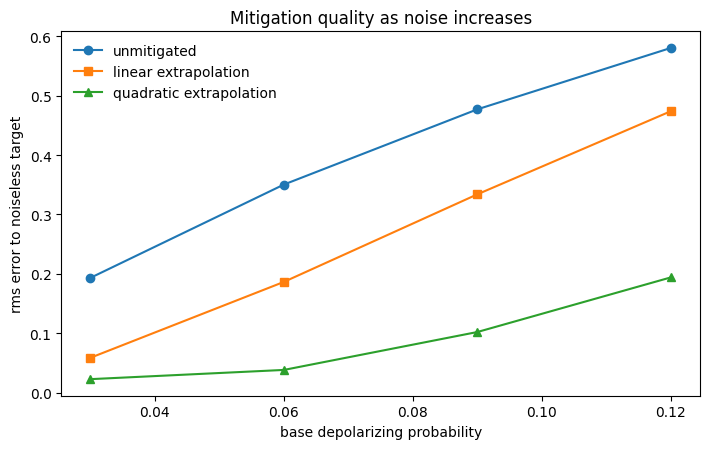

In [11]:
stress_levels = [0.03, 0.06, 0.09, 0.12]
stress_unmitigated, stress_linear, stress_quadratic = [], [], []
for level in stress_levels:
    squared_un, squared_lin, squared_quad = [], [], []
    for sample in X_test:
        ideal = float(model_exact(sample, weights, 0.0))
        scales, values = collect_noise_curve(sample, scale_factors, level, repeats_per_scale)
        base_value = float(np.mean(values[scales == 1.0]))
        (lin_point,), _, _ = polynomial_extrapolation(scales, values, 1, [0.0])
        (quad_point,), _, _ = polynomial_extrapolation(scales, values, 2, [0.0])
        squared_un.append((base_value - ideal) ** 2)
        squared_lin.append((lin_point - ideal) ** 2)
        squared_quad.append((quad_point - ideal) ** 2)
    stress_unmitigated.append(np.sqrt(np.mean(squared_un)))
    stress_linear.append(np.sqrt(np.mean(squared_lin)))
    stress_quadratic.append(np.sqrt(np.mean(squared_quad)))
    print("base noise", level,
          "unmitigated", round(stress_unmitigated[-1], 4),
          "linear", round(stress_linear[-1], 4),
          "quadratic", round(stress_quadratic[-1], 4))

figure2, axis2 = plt.subplots(figsize=(7.2, 4.6))
axis2.plot(stress_levels, stress_unmitigated, marker="o", label="unmitigated")
axis2.plot(stress_levels, stress_linear, marker="s", label="linear extrapolation")
axis2.plot(stress_levels, stress_quadratic, marker="^", label="quadratic extrapolation")
axis2.set_xlabel("base depolarizing probability")
axis2.set_ylabel("rms error to noiseless target")
axis2.set_title("Mitigation quality as noise increases")
axis2.legend(frameon=False)
figure2.tight_layout()
plt.show()